In [10]:
!pip install requests pandas numpy matplotlib

In [11]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE_URL = "https://api.openf1.org/v1"

response = requests.get(
    f"{BASE_URL}/sessions",
    params={
        "year": 2024,
        "country_name": "Italy",
        "session_name": "Qualifying"
    },
    timeout=30
)

response.raise_for_status()

sessions = response.json()

print("Sessions found:", len(sessions))
print(pd.DataFrame(sessions)[
    ['session_key', 'session_name', 'circuit_short_name', 'date_start']
])

Sessions found: 2
   session_key session_name circuit_short_name                 date_start
0         9511   Qualifying              Imola  2024-05-18T14:00:00+00:00
1         9586   Qualifying              Monza  2024-08-31T14:00:00+00:00


In [12]:
# Get session ID
session_key = sessions[0]['session_key']

# Get driver information
response = requests.get(
    f"{BASE_URL}/drivers",
    params={"session_key": session_key},
    timeout=30
)

response.raise_for_status()

drivers = pd.DataFrame(response.json())

charles = drivers[
    drivers['name_acronym'] == 'LEC'
]

print(charles[['full_name', 'team_name', 'driver_number']])

         full_name team_name  driver_number
7  Charles LECLERC   Ferrari             16


In [13]:
response = requests.get(
    f"{BASE_URL}/laps",
    params={
        "session_key": session_key,
        "driver_number": 16
    },
    timeout=30
)

response.raise_for_status()

laps = pd.DataFrame(response.json())

# Remove incomplete laps
valid_laps = laps.dropna(subset=['lap_duration'])

# Find fastest lap
fastest_lap = valid_laps.loc[
    valid_laps['lap_duration'].idxmin()
]

print("Driver: Charles Leclerc")
print("Lap Number:", fastest_lap['lap_number'])
print("Lap Time:", fastest_lap['lap_duration'])
print("Lap Start:", fastest_lap['date_start'])

Driver: Charles Leclerc
Lap Number: 20
Lap Time: 74.97
Lap Start: 2024-05-18T14:58:31.386000+00:00


In [14]:
# Fetch all 2024 qualifying sessions
response = requests.get(
    f"{BASE_URL}/sessions",
    params={
        "year": 2024,
        "session_name": "Qualifying"
    }
)

response.raise_for_status()

all_sessions = pd.DataFrame(response.json())

# Find Monza qualifying
monza = all_sessions[
    all_sessions['circuit_short_name'].str.lower() == 'monza'
]

print(monza[[
    'session_key',
    'country_name',
    'circuit_short_name',
    'date_start'
]])

    session_key country_name circuit_short_name                 date_start
15         9586        Italy              Monza  2024-08-31T14:00:00+00:00


In [15]:
session_key = int(monza.iloc[0]['session_key'])

print("Correct Monza session:", session_key)

Correct Monza session: 9586


In [16]:
response = requests.get(
    f"{BASE_URL}/laps",
    params={
        "session_key": session_key,
        "driver_number": 16
    }
)

response.raise_for_status()

laps = pd.DataFrame(response.json())

valid_laps = laps.dropna(subset=['lap_duration'])

fastest_lap = valid_laps.loc[
    valid_laps['lap_duration'].idxmin()
]

print("Driver: Charles Leclerc")
print("Lap:", fastest_lap['lap_number'])
print("Lap Time:", fastest_lap['lap_duration'])
print("Lap Start:", fastest_lap['date_start'])

Driver: Charles Leclerc
Lap: 20
Lap Time: 79.461
Lap Start: 2024-08-31T15:03:09.963000+00:00


In [18]:
test_response = requests.get(
    f"{BASE_URL}/location",
    params={
        "session_key": session_key,
        "driver_number": 16
    },
    timeout=60
)

print("Status:", test_response.status_code)
print("Response:", test_response.text[:500])

Status: 200
Response: [{"date":"2024-08-31T13:49:25.147000+00:00","session_key":9586,"meeting_key":1244,"driver_number":16,"x":0,"z":0,"y":0},{"date":"2024-08-31T13:49:25.467000+00:00","session_key":9586,"meeting_key":1244,"driver_number":16,"x":0,"z":0,"y":0},{"date":"2024-08-31T13:49:25.727000+00:00","session_key":9586,"meeting_key":1244,"driver_number":16,"x":0,"z":0,"y":0},{"date":"2024-08-31T13:49:26.027000+00:00","session_key":9586,"meeting_key":1244,"driver_number":16,"x":0,"z":0,"y":0},{"date":"2024-08-31T13:


In [19]:
if test_response.status_code == 200:
    location_df = pd.DataFrame(test_response.json())

    print("Location records:", len(location_df))
    print(location_df.head())
else:
    print("Location data is unavailable for this session.")

Location records: 18239
                               date  session_key  meeting_key  driver_number  \
0  2024-08-31T13:49:25.147000+00:00         9586         1244             16   
1  2024-08-31T13:49:25.467000+00:00         9586         1244             16   
2  2024-08-31T13:49:25.727000+00:00         9586         1244             16   
3  2024-08-31T13:49:26.027000+00:00         9586         1244             16   
4  2024-08-31T13:49:26.207000+00:00         9586         1244             16   

   x  z  y  
0  0  0  0  
1  0  0  0  
2  0  0  0  
3  0  0  0  
4  0  0  0  


In [20]:
car_test = requests.get(
    f"{BASE_URL}/car_data",
    params={
        "session_key": session_key,
        "driver_number": 16
    },
    timeout=60
)

print("Car data status:", car_test.status_code)
print("Response:", car_test.text[:300])

Car data status: 200
Response: [{"date":"2024-08-31T13:50:11.714000+00:00","session_key":9586,"speed":0,"driver_number":16,"meeting_key":1244,"rpm":0,"brake":0,"throttle":0,"drs":0,"n_gear":0},{"date":"2024-08-31T13:50:12.074000+00:00","session_key":9586,"speed":0,"driver_number":16,"meeting_key":1244,"rpm":0,"brake":0,"throttle"


In [21]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE_URL = "https://api.openf1.org/v1"

# Use the fastest_lap and session_key variables from your previous cells
lap_start = pd.to_datetime(fastest_lap["date_start"], utc=True)
lap_duration = float(fastest_lap["lap_duration"])
lap_end = lap_start + pd.Timedelta(seconds=lap_duration)

# Add a 10-second buffer on both sides
start_time = (lap_start - pd.Timedelta(seconds=10)).strftime("%Y-%m-%dT%H:%M:%S")
end_time = (lap_end + pd.Timedelta(seconds=10)).strftime("%Y-%m-%dT%H:%M:%S")

params = {
    "session_key": session_key,
    "driver_number": 16,
    "date>": start_time,
    "date<": end_time
}

# Fetch position data
response = requests.get(f"{BASE_URL}/location", params=params, timeout=60)
print("Location status:", response.status_code)
response.raise_for_status()
location_df = pd.DataFrame(response.json())

# Fetch speed, throttle and brake data
response = requests.get(f"{BASE_URL}/car_data", params=params, timeout=60)
print("Car data status:", response.status_code)
response.raise_for_status()
car_df = pd.DataFrame(response.json())

print("Location samples:", len(location_df))
print("Car telemetry samples:", len(car_df))
print("Lap duration:", round(lap_duration, 3), "seconds")

Location status: 200
Car data status: 200
Location samples: 404
Car telemetry samples: 392
Lap duration: 79.461 seconds


In [22]:
# Convert timestamps to datetime
location_df["date"] = pd.to_datetime(location_df["date"], utc=True)
car_df["date"] = pd.to_datetime(car_df["date"], utc=True)

# Keep samples within the selected lap
location_df = location_df[
    (location_df["date"] >= lap_start) &
    (location_df["date"] <= lap_end)
].copy()

car_df = car_df[
    (car_df["date"] >= lap_start) &
    (car_df["date"] <= lap_end)
].copy()

# Remove invalid position samples
location_df = location_df[
    (location_df["x"] != 0) | (location_df["y"] != 0)
].copy()

location_df = location_df.sort_values("date")
car_df = car_df.sort_values("date")

# Match position to the nearest telemetry reading
telemetry = pd.merge_asof(
    location_df,
    car_df[["date", "speed", "brake", "throttle", "n_gear"]],
    on="date",
    direction="nearest",
    tolerance=pd.Timedelta("600ms")
)

telemetry = telemetry.dropna(subset=["speed"])
telemetry = telemetry.drop_duplicates(subset=["date"])

print("Matched telemetry samples:", len(telemetry))
display(telemetry.head())

Matched telemetry samples: 321


,date,session_key,driver_number,meeting_key,x,z,y,speed,brake,throttle,n_gear
0,2024-08-31 15:03:10.289000+00:00,9586,16,1244,-1339,1873,-278,325,0,100,8
1,2024-08-31 15:03:10.449000+00:00,9586,16,1244,-1315,1875,-7,325,0,100,8
2,2024-08-31 15:03:10.929000+00:00,9586,16,1244,-1288,1876,301,329,0,100,8
3,2024-08-31 15:03:11.008000+00:00,9586,16,1244,-1282,1877,374,329,0,100,8
4,2024-08-31 15:03:11.168000+00:00,9586,16,1244,-1269,1877,521,333,0,99,8


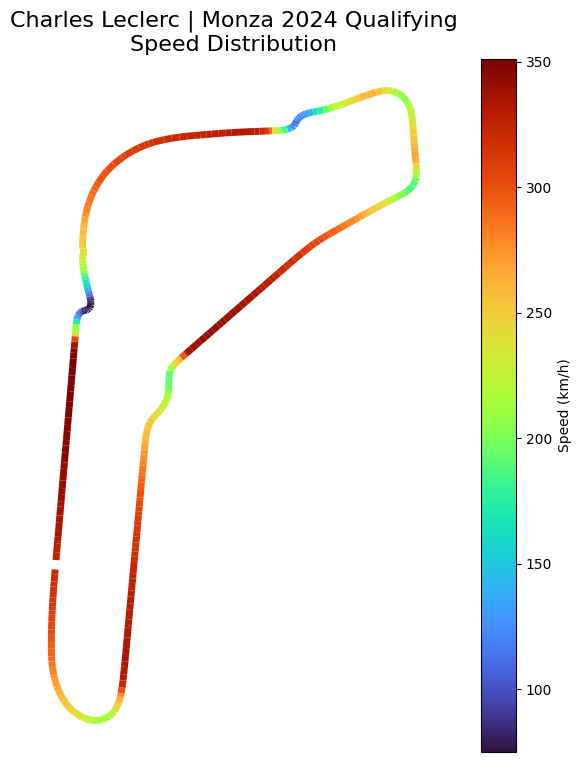

In [25]:
from matplotlib.collections import LineCollection
import matplotlib.pyplot as plt
import numpy as np

plot_df = telemetry.dropna(subset=["x", "y", "speed"]).copy()

x = plot_df["x"].to_numpy()
y = plot_df["y"].to_numpy()
speed = plot_df["speed"].to_numpy()

points = np.array([x, y]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

fig, ax = plt.subplots(figsize=(12, 9))

line = LineCollection(
    segments,
    cmap="turbo",
    linewidth=5
)

line.set_array((speed[:-1] + speed[1:]) / 2)

ax.add_collection(line)
ax.autoscale()
ax.set_aspect("equal")
ax.axis("off")

cbar = fig.colorbar(line, ax=ax)
cbar.set_label("Speed (km/h)")

ax.set_title(
    "Charles Leclerc | Monza 2024 Qualifying\nSpeed Distribution",
    fontsize=16
)

plt.show()

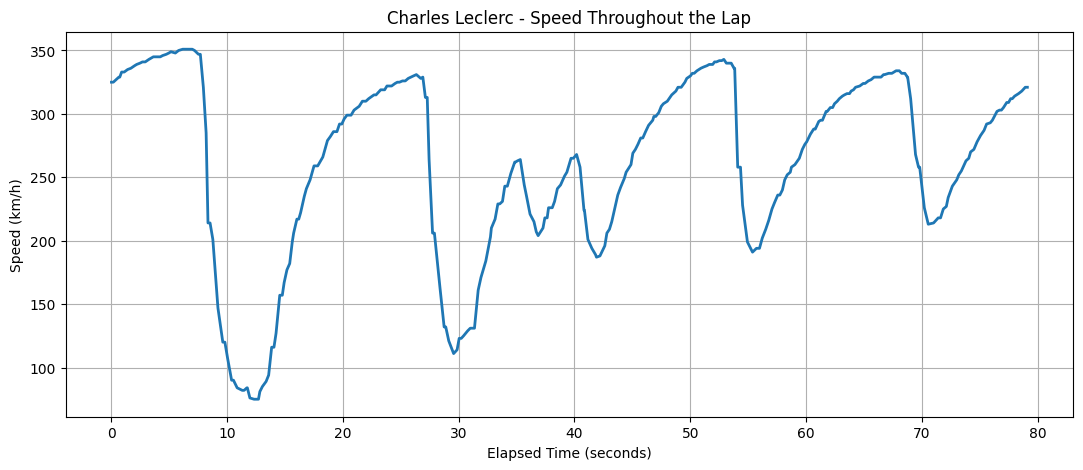

In [28]:
telemetry = telemetry.sort_values("date").copy()

telemetry["elapsed_time"] = (
    telemetry["date"] - telemetry["date"].iloc[0]
).dt.total_seconds()

plt.figure(figsize=(13, 5))

plt.plot(
    telemetry["elapsed_time"],
    telemetry["speed"],
    linewidth=2
)

plt.title("Charles Leclerc - Speed Throughout the Lap")
plt.xlabel("Elapsed Time (seconds)")
plt.ylabel("Speed (km/h)")
plt.grid(True)

plt.show()

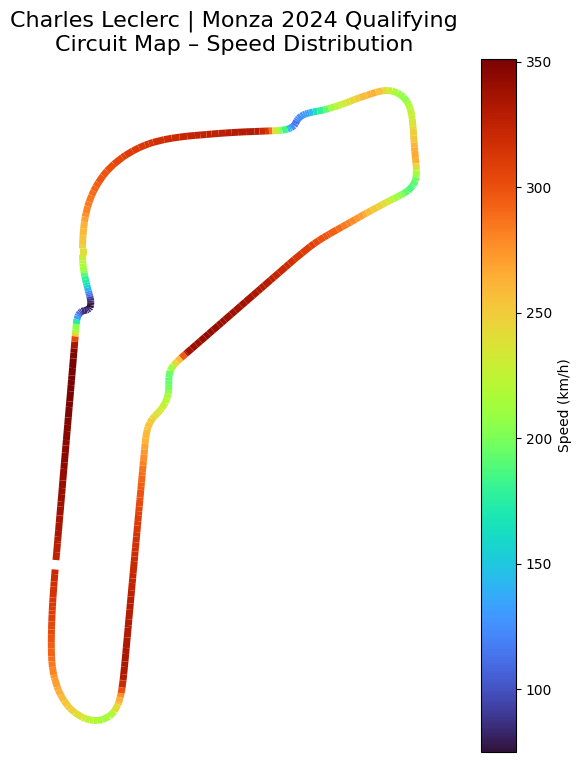

In [29]:
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
import numpy as np
import matplotlib.pyplot as plt

plot_df = telemetry.dropna(subset=["x", "y", "speed"]).copy()

x = plot_df["x"].to_numpy()
y = plot_df["y"].to_numpy()
speed = plot_df["speed"].to_numpy()

points = np.column_stack([x, y]).reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

fig, ax = plt.subplots(figsize=(12, 9))

line = LineCollection(
    segments,
    cmap="turbo",
    norm=Normalize(speed.min(), speed.max())
)

line.set_array((speed[:-1] + speed[1:]) / 2)
line.set_linewidth(5)

ax.add_collection(line)
ax.autoscale()
ax.set_aspect("equal")
ax.axis("off")

cbar = fig.colorbar(line, ax=ax)
cbar.set_label("Speed (km/h)")

ax.set_title(
    "Charles Leclerc | Monza 2024 Qualifying\n"
    "Circuit Map – Speed Distribution",
    fontsize=16
)

plt.show()

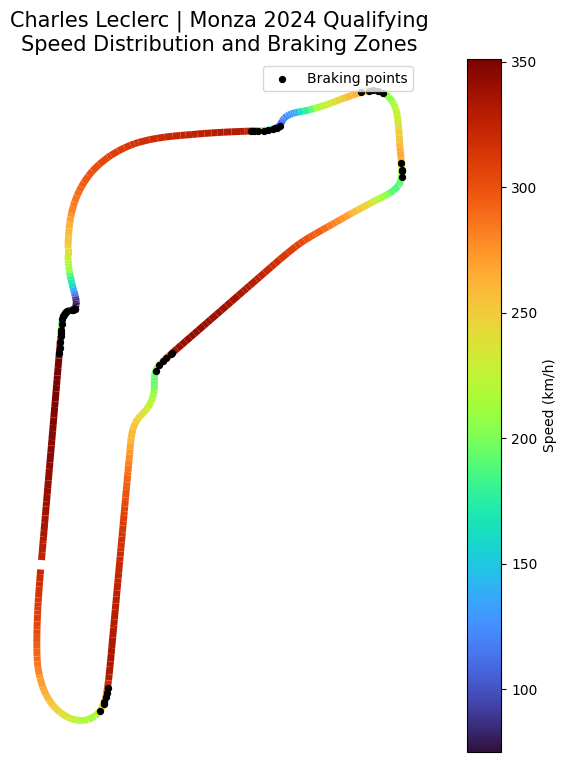

Number of braking samples: 47


In [30]:
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
import matplotlib.pyplot as plt
import numpy as np

plot_df = telemetry.dropna(
    subset=["x", "y", "speed", "brake"]
).copy()

x = plot_df["x"].to_numpy()
y = plot_df["y"].to_numpy()
speed = plot_df["speed"].to_numpy()

# Create coloured track segments
points = np.column_stack([x, y]).reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

fig, ax = plt.subplots(figsize=(12, 9))

line = LineCollection(
    segments,
    cmap="turbo",
    norm=Normalize(speed.min(), speed.max())
)

line.set_array((speed[:-1] + speed[1:]) / 2)
line.set_linewidth(5)

ax.add_collection(line)

# Identify braking positions
braking = plot_df[plot_df["brake"] >= 50]

ax.scatter(
    braking["x"],
    braking["y"],
    color="black",
    s=18,
    label="Braking points",
    zorder=5
)

ax.autoscale()
ax.set_aspect("equal")
ax.axis("off")

cbar = fig.colorbar(line, ax=ax)
cbar.set_label("Speed (km/h)")

ax.set_title(
    "Charles Leclerc | Monza 2024 Qualifying\n"
    "Speed Distribution and Braking Zones",
    fontsize=15
)

ax.legend(loc="upper right")
plt.show()

print("Number of braking samples:", len(braking))

In [31]:
import pandas as pd
import numpy as np

# Prepare the telemetry data
df = telemetry.sort_values("date").copy()

# Calculate elapsed time
df["elapsed_time"] = (
    df["date"] - df["date"].iloc[0]
).dt.total_seconds()

# Calculate performance metrics
max_speed = df["speed"].max()
min_speed = df["speed"].min()
avg_speed = df["speed"].mean()
median_speed = df["speed"].median()

# Calculate braking information
braking_data = df[df["brake"] >= 50]

# Calculate time spent in different speed ranges
speed_ranges = {
    "Low speed (below 150 km/h)": (df["speed"] < 150).sum(),
    "Medium speed (150–250 km/h)": (
        (df["speed"] >= 150) & (df["speed"] < 250)
    ).sum(),
    "High speed (250–300 km/h)": (
        (df["speed"] >= 250) & (df["speed"] < 300)
    ).sum(),
    "Very high speed (300+ km/h)": (df["speed"] >= 300).sum()
}

print("🏎️ CHARLES LECLERC - MONZA PERFORMANCE ANALYSIS")
print("-" * 45)

print(f"Maximum Speed: {max_speed:.2f} km/h")
print(f"Minimum Speed: {min_speed:.2f} km/h")
print(f"Average Speed: {avg_speed:.2f} km/h")
print(f"Median Speed: {median_speed:.2f} km/h")
print(f"Braking Samples: {len(braking_data)}")

print("\nSpeed Distribution:")
for category, count in speed_ranges.items():
    percentage = count / len(df) * 100
    print(f"{category}: {percentage:.1f}% of samples")

🏎️ CHARLES LECLERC - MONZA PERFORMANCE ANALYSIS
---------------------------------------------
Maximum Speed: 351.00 km/h
Minimum Speed: 75.00 km/h
Average Speed: 262.20 km/h
Median Speed: 281.00 km/h
Braking Samples: 47

Speed Distribution:
Low speed (below 150 km/h): 10.9% of samples
Medium speed (150–250 km/h): 25.9% of samples
High speed (250–300 km/h): 21.8% of samples
Very high speed (300+ km/h): 41.4% of samples


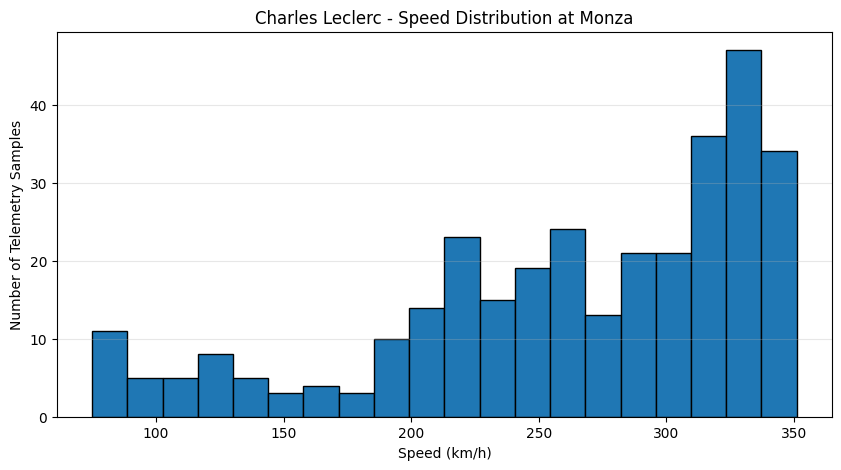

In [32]:
plt.figure(figsize=(10, 5))

plt.hist(
    df["speed"],
    bins=20,
    edgecolor="black"
)

plt.title("Charles Leclerc - Speed Distribution at Monza")
plt.xlabel("Speed (km/h)")
plt.ylabel("Number of Telemetry Samples")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [33]:
df.to_csv(
    "Charles_Leclerc_Monza_Telemetry.csv",
    index=False
)

print("CSV file created successfully!")

CSV file created successfully!
